# SI Fig. S4: binning and fitting for Expt 1

S4b  reads per barcode at t0, and reads per virtual lineage after combining
       barcodes into k bins.  Combining converts a distribution spanning decades into
       one sharply peaked at total/k, which is what lets the data be compared against
       a theory that assumes a single population size N.

  S4d  the least-squares CCDF loss profiled over each of mu and alpha.
  S4e  the same for the Laplace-space fit, which uses the closed form of SI Eq. 8 and
       needs no simulation.

  S4f  best-fit mu and alpha at each bin count, with 95% bootstrap intervals.
       Consistency across bin counts is the internal check on the fit: one mu should
       describe the data at every N.

Also caches the fit for Fig. 2 and Fig. 5.

Runtime: ~4 min, dominated by simulating the LD distribution over the mu grid.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import time

import numpy as np
import matplotlib.pyplot as plt

from barfly import expt1, fitting, ld                                 # noqa: E402
from barfly.plotting import (bin_count_colour, colorTable,
                               use_paper_style)                         # noqa: E402

OUTPUT_DIR = ROOT / "output"
CACHE_DIR = ROOT / "cache"

BIN_COUNTS = np.array([80000, 40000, 20000, 10000, 5000, 2500, 1250])

# The mu grid is centred on this rate, wide enough either side that the optimum stays
# interior at every bin count.
MU_REFERENCE = 5.5e-7

In [2]:
def plot_read_distributions(counts_pre, binned_pre, n_bin_counts):
    """S4b: reads per barcode, and reads per virtual lineage at each bin count."""
    _, axis = plt.subplots(figsize=(6, 4))
    hist_bins = np.logspace(np.log10(counts_pre.min()), np.log10(counts_pre.max()), 40)
    axis.hist(counts_pre, bins=hist_bins, color=colorTable['k'])
    axis.set_xscale('log')
    axis.set_xlabel('reads per barcode at $t_0$')
    axis.set_ylabel('number of barcodes')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figS04b_t0RawCounts.svg", dpi=300)
    plt.show()

    _, axis = plt.subplots(figsize=(9, 4))
    all_binned = np.concatenate([binned_pre[i] for i in range(n_bin_counts)])
    hist_bins = np.logspace(np.log10(all_binned[all_binned > 0].min()),
                            np.log10(all_binned.max()), 60)
    for i_k, n_bins in enumerate(BIN_COUNTS):
        axis.hist(binned_pre[i_k], bins=hist_bins, histtype='step', linewidth=2,
                  weights=np.ones(len(binned_pre[i_k])) / len(binned_pre[i_k]),
                  color=bin_count_colour(i_k, n_bin_counts), label=f'k = {n_bins}')
    axis.set_xscale('log')
    axis.set_xlabel('reads per bin at $t_0$')
    axis.set_ylabel('fraction of bins')
    axis.legend(fontsize=11, ncol=2)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figS04b_t0BinnedCounts.svg", dpi=300)
    plt.show()

In [3]:
def plot_loss_profiles(loss, alpha_values, mu_values, filename):
    """S4d, S4e: loss profiled over whichever parameter is not on the axis."""
    _, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
    axes[0].plot(alpha_values, np.min(loss, axis=0), '.', color=colorTable['k'],
                 markersize=13)
    axes[0].set_xscale('log')
    axes[0].set_yscale('log')
    axes[0].set_xlabel(r'$\alpha$')
    axes[0].set_ylabel('sqr. err.')
    axes[1].plot(mu_values, np.min(loss, axis=1), '.', color=colorTable['k'],
                 markersize=13)
    axes[1].set_xscale('log')
    axes[1].set_xlabel(r'$\mu$')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=300)
    plt.show()

In [4]:
def plot_best_fits(mu_ccdf, mu_laplace, n_bin_counts):
    """S4f: best-fit mu and alpha against bin count, with 95% bootstrap intervals.

    Point estimates and intervals both come from the bootstrap replicates, so that
    every interval brackets its own point.  The bootstrap used a finer parameter grid
    and more simulation replicates than the fit above, hence small differences.

    `boot` is indexed (replicate, estimator, bin count, parameter): estimator 0 is the
    CCDF fit and 1 the Laplace fit, bin-count row -1 is the global fit, and parameter
    0 is mu, 1 is alpha.
    """
    bootstrap = np.load(ROOT / "data" / "bootstrap" / "20260801_expt1_bootstrap.npz")
    assert np.array_equal(bootstrap['kvec'], BIN_COUNTS)

    points = {(estimator, parameter): bootstrap['point'][estimator, :, parameter]
              for estimator in (0, 1) for parameter in (0, 1)}
    errors = {key: fitting.percentile_interval(
                       points[key], bootstrap['boot'][:, key[0], :, key[1]])
              for key in points}

    print(f"\nbootstrap: B = {int(bootstrap['B'])} replicates")
    print(f"global mu, CCDF fit:    script {mu_ccdf[-1]:.3e}, "
          f"bootstrap {points[(0, 0)][-1]:.3e}")
    print(f"global mu, Laplace fit: script {mu_laplace[-1]:.3e}, "
          f"bootstrap {points[(1, 0)][-1]:.3e}")
    # At small bin counts mu*N is large enough that almost no lineage is mutant-free,
    # so the zero-mutant fraction no longer pins alpha for the CCDF fit.
    print(f"CCDF-fit rows without a live alpha anchor: k = {bootstrap['unanchored']}")

    positions = np.arange(n_bin_counts + 1)
    labels = [str(n) for n in BIN_COUNTS] + ['global']
    panels = [("figS04f_bestFitMu.svg", r'best-fit $\mu$', (1e-6, 1e-5)),
              ("figS04f_bestFitAlpha.svg", r'best-fit $\alpha$', (0.1, 10))]
    for parameter, (filename, label, y_limits) in enumerate(panels):
        _, axis = plt.subplots(figsize=(8, 4))
        for estimator, colour, name, offset in (
                (0, '0.6', 'cumulative', -0.15),
                (1, colorTable['k'], 'Laplace', +0.15)):
            axis.errorbar(positions + offset, points[(estimator, parameter)],
                          yerr=errors[(estimator, parameter)], fmt='o', markersize=11,
                          color=colour, ecolor=colour, elinewidth=2, capsize=4,
                          label=name)
        axis.set_yscale('log')
        axis.set_ylim(*y_limits)
        axis.set_xticks(positions)
        axis.set_xticklabels(labels, rotation=45)
        axis.set_xlim(-0.6, n_bin_counts + 0.6)
        axis.set_xlabel('k bins')
        axis.set_ylabel(label)
        axis.legend(fontsize=11)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / filename, dpi=300)
        plt.show()

In [5]:
started = time.time()
use_paper_style()
OUTPUT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)
n_bin_counts = len(BIN_COUNTS)

_, counts_pre, counts_post, reads_post = expt1.load()
print(f"{len(counts_pre)} barcodes pass the cutoffs")
# Reads to absolute mutant numbers, SI Eq. 10.  A lineage's share of the final-time
# reads, scaled to the plated mutant count M_cfu, times the calibration factor alpha.
# reads_post spans every barcode passing the lower cutoff, so the ratio is taken
# against the same population M_cfu was sampled from.
total_mutants = (np.sum(counts_post) / reads_post) * expt1.PLATED_CFU
print(f"total mutants at alpha = 1: {total_mutants:.0f}")

# Combine barcodes into virtual lineages of near-equal founding size, at each bin
# count, and convert each lineage's reads to a mutant number.
binned_pre, mutants_by_bin_count = {}, {}
for i_k, n_bins in enumerate(BIN_COUNTS):
    _, pre, post = ld.bin_barcodes(counts_pre, counts_post, n_bins)
    binned_pre[i_k] = pre
    mutants_by_bin_count[i_k] = total_mutants * post / np.sum(post)
print(f"binning done ({time.time() - started:.0f}s)")

thresholds, largest_scored = fitting.ccdf_thresholds(mutants_by_bin_count)
print(f"CCDF scored up to {largest_scored:.0f} mutants")

mu_values = np.logspace(np.log10(MU_REFERENCE / 4),
                        np.log10(MU_REFERENCE * 20), 100)
alpha_values = np.logspace(-1, 1, 50)
# The Laplace fit is analytic, so it can afford a finer grid than the
# simulation-bound CCDF fit.
mu_values_laplace = np.logspace(-7, -5, 100)
alpha_values_laplace = np.logspace(-1, 1, 100)

step = time.time()
simulations = fitting.simulate_over_mu(mu_values, BIN_COUNTS,
                                       expt1.TOTAL_CELLS, label="expt1")
print(f"simulations done ({time.time() - step:.0f}s)")

step = time.time()
ccdf_loss = fitting.ccdf_loss(mutants_by_bin_count, simulations, mu_values,
                              alpha_values, thresholds)
mu_ccdf, alpha_ccdf = fitting.best_fit_per_bin_count(ccdf_loss, mu_values,
                                                     alpha_values)
print(f"CCDF fit: mu = {mu_ccdf[-1]:.3e}, alpha = {alpha_ccdf[-1]:.3f} "
      f"({time.time() - step:.0f}s)")

step = time.time()
laplace_loss = fitting.laplace_loss(mutants_by_bin_count, BIN_COUNTS,
                                    mu_values_laplace, alpha_values_laplace,
                                    expt1.TOTAL_CELLS)
mu_laplace, alpha_laplace = fitting.best_fit_per_bin_count(
    laplace_loss, mu_values_laplace, alpha_values_laplace)
print(f"Laplace fit: mu = {mu_laplace[-1]:.3e}, "
      f"alpha = {alpha_laplace[-1]:.3f} ({time.time() - step:.0f}s)")

119672 barcodes pass the cutoffs
total mutants at alpha = 1: 46266


binning done (3s)
CCDF scored up to 1324 mutants


simulations done (90s)


CCDF fit: mu = 2.046e-06, alpha = 4.292 (3s)


Laplace fit: mu = 2.154e-06, alpha = 4.535 (3s)


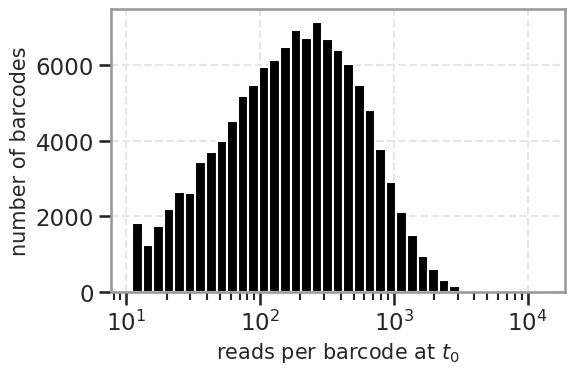

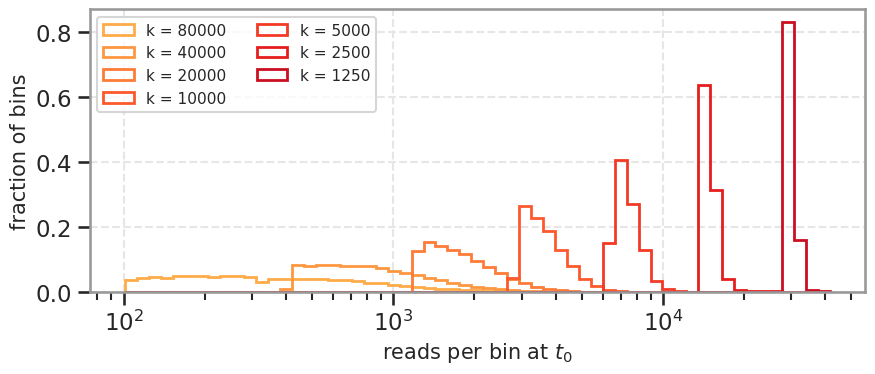

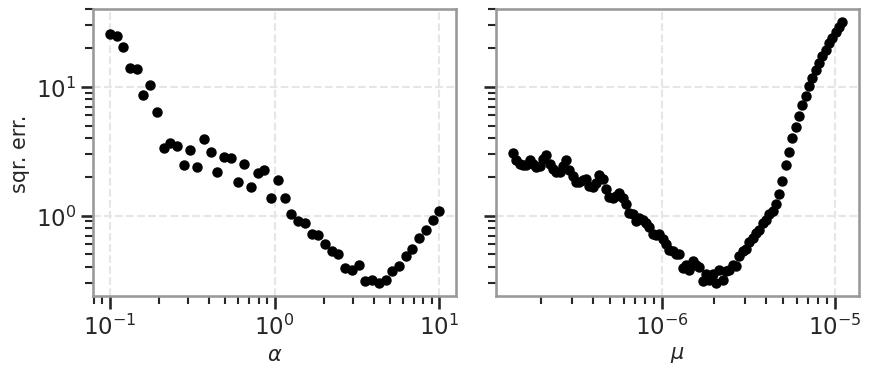

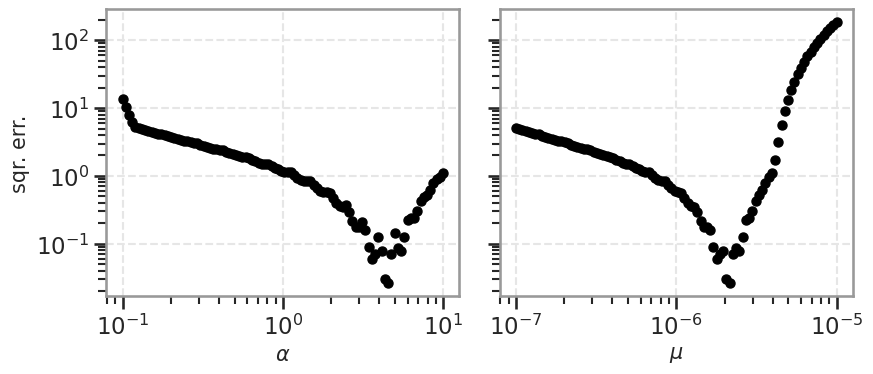


bootstrap: B = 10000 replicates
global mu, CCDF fit:    script 2.046e-06, bootstrap 2.038e-06
global mu, Laplace fit: script 2.154e-06, bootstrap 2.122e-06
CCDF-fit rows without a live alpha anchor: k = [2500 1250]


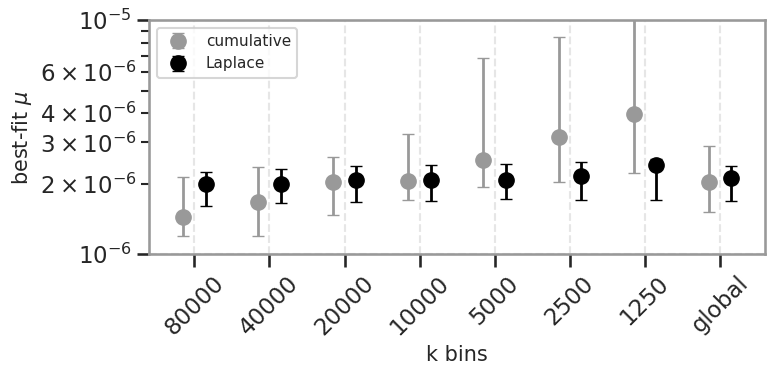

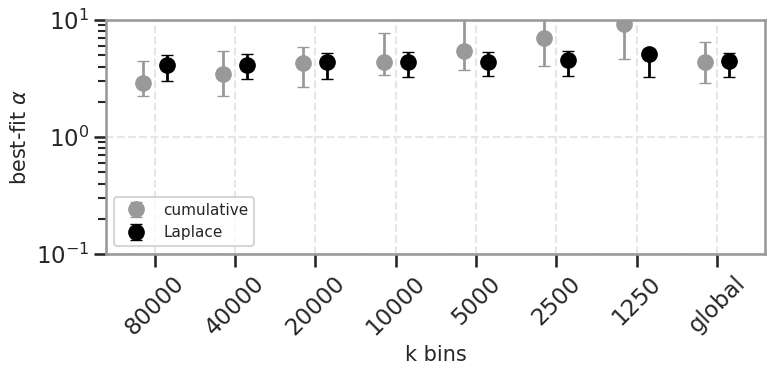

Done in 100s.


In [6]:
# Consumed by 20260907_fig02_expt1.py (all five) and 20260907_fig05_dmus.py
# (mu_ls, alpha_ls).  The last entry of each array is the global fit.
np.savez(CACHE_DIR / "expt1_fit.npz",
         kvec=BIN_COUNTS,
         mu_ls=mu_ccdf, alpha_ls=alpha_ccdf,
         mu_lap=mu_laplace, alpha_lap=alpha_laplace)

plot_read_distributions(counts_pre, binned_pre, n_bin_counts)
plot_loss_profiles(ccdf_loss.sum(axis=0), alpha_values, mu_values,
                   "figS04d_lossProfilesLS.svg")
plot_loss_profiles(laplace_loss.sum(axis=0), alpha_values_laplace,
                   mu_values_laplace, "figS04e_lossProfilesLaplace.svg")
plot_best_fits(mu_ccdf, mu_laplace, n_bin_counts)

print(f"Done in {time.time() - started:.0f}s.")

In [7]:
sys.path.insert(0, str(ROOT))